In [9]:
import os, sys

sys.path.insert(0, os.path.abspath(os.getcwd() + "/../build/python/"))
print(os.path.abspath(os.getcwd() + "/../build/python/"))
import pyqedfv as qedfv
import numpy as np
from scipy.optimize import curve_fit
from scipy.special import zeta
import matplotlib.pyplot as plt
from tqdm.notebook import tnrange, tqdm

# plt.rcParams['text.usetex'] = True
%config InlineBackend.figure_formats = ['svg']

/Users/antonin/Development/QedFvCoef/build/python


In [10]:
cqedr = qedfv.Coef(qed=qedfv.Qed.L)

In [11]:
def cjVsVel(j, dir, nPoints, expMin=0, expMax=15, residual=1.0e-4):
    vn = np.linspace(expMin, expMax, nPoints)
    vn = np.power(10.0, -vn)
    dir /= np.linalg.norm(dir)
    cj = np.zeros(nPoints)
    par = cqedr.tune(j, (1 - vn[0]) * dir, residual=residual)
    for i in tnrange(nPoints):
        cj[i] = cqedr(j, (1 - vn[i]) * dir, par)
        par = cqedr.tune(j, (1 - vn[i]) * dir, par, residual=residual)
    return np.array([vn, cj])

16.52253804899211


  0%|          | 0/300 [00:00<?, ?it/s]

1.4142135623730951


/var/folders/vc/2xf3h5rx0nb_6w0v8b6svf080000gn/T/ipykernel_15057/3005758107.py:18: RuntimeWarning: invalid value encountered in divide
  sw = cj0 * np.arctanh(1 - cj[0]) / (1 - cj[0])


  0%|          | 0/300 [00:00<?, ?it/s]

  0%|          | 0/300 [00:00<?, ?it/s]

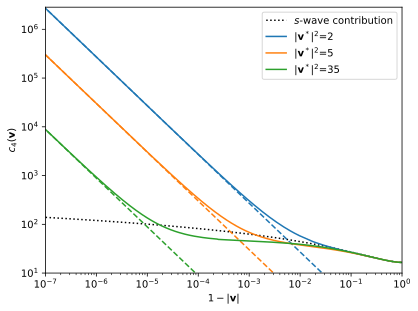

In [12]:
def model(x, a, p):
    return a / x**p


def relDiff(a, b):
    return np.abs(a - b) / (0.5 * np.abs(a + b))


j = 4
z2 = zeta(j)
nPoints = 300
expMax = 7
par = cqedr.tune(j, residual=1.0e-2)
cj0 = cqedr(j, par)
print(cj0)
dir = [1, 1, 0]
cj = cjVsVel(j, dir, nPoints, residual=1.0e-2, expMax=expMax)
sw = cj0 * np.arctanh(1 - cj[0]) / (1 - cj[0])
print(np.linalg.norm(dir))
plt.plot(cj[0], sw, color="black", linestyle=":", label=r"$s$-wave contribution")
plt.plot(
    cj[0],
    cj[1],
    color="C0",
    label=(r"$|\mathbf{v}^*|^2$=%d" % (np.linalg.norm(dir) ** 2)),
)
plt.plot(
    cj[0], model(cj[0], z2 / np.linalg.norm(dir) ** j, 1), color="C0", linestyle="--"
)
dir = [1, 2, 1]
cj = cjVsVel(j, dir, nPoints, residual=1.0e-2, expMax=expMax)
plt.plot(
    cj[0],
    cj[1],
    color="C1",
    label=(r"$|\mathbf{v}^*|^2$=%d" % (np.linalg.norm(dir) ** 2)),
)
plt.plot(
    cj[0], model(cj[0], z2 / np.linalg.norm(dir) ** j, 1), color="C1", linestyle="--"
)
dir = [1, 3, 5]
cj = cjVsVel(j, dir, nPoints, residual=1.0e-2, expMax=expMax)
plt.plot(
    cj[0],
    cj[1],
    color="C2",
    label=(r"$|\mathbf{v}^*|^2$=%d" % (np.linalg.norm(dir) ** 2)),
)
plt.plot(
    cj[0], model(cj[0], z2 / np.linalg.norm(dir) ** j, 1), color="C2", linestyle="--"
)
plt.xscale("log")
plt.yscale("symlog")
plt.xlabel(r"$1-|\mathbf{v}|$")
plt.ylabel(r"$c_%d(\mathbf{v})$" % (j))
plt.xlim(10.0 ** (-expMax), 1.0)
plt.ylim(bottom=10)
plt.legend()
plt.show()

In [ ]:
def model(x, a, p):
    return a / x**p


def relDiff(a, b):
    return np.abs(a - b) / (0.5 * np.abs(a + b))


j = 2
z2 = zeta(j)
nPoints = 300
expMax = 7
par = cqedr.tune(j, residual=1.0e-2)
cj0 = cqedr(j, par)
print(cj0)
dir = [1, 1, 0]
cj = cjVsVel(j, dir, nPoints, residual=1.0e-2, expMax=expMax)
sw = cj0 * np.arctanh(1 - cj[0]) / (1 - cj[0])
print(np.linalg.norm(dir))
plt.plot(cj[0], sw, color="black", linestyle=":", label=r"$s$-wave contribution")
plt.plot(
    cj[0],
    cj[1],
    color="C0",
    label=(r"$|\mathbf{v}^*|^2$=%d" % (np.linalg.norm(dir) ** 2)),
)
plt.plot(
    cj[0], model(cj[0], z2 / np.linalg.norm(dir) ** j, 1), color="C0", linestyle="--"
)
dir = [1, 2, 1]
cj = cjVsVel(j, dir, nPoints, residual=1.0e-2, expMax=expMax)
plt.plot(
    cj[0],
    cj[1],
    color="C1",
    label=(r"$|\mathbf{v}^*|^2$=%d" % (np.linalg.norm(dir) ** 2)),
)
plt.plot(
    cj[0], model(cj[0], z2 / np.linalg.norm(dir) ** j, 1), color="C1", linestyle="--"
)
dir = [1, 3, 5]
cj = cjVsVel(j, dir, nPoints, residual=1.0e-2, expMax=expMax)
plt.plot(
    cj[0],
    cj[1],
    color="C2",
    label=(r"$|\mathbf{v}^*|^2$=%d" % (np.linalg.norm(dir) ** 2)),
)
plt.plot(
    cj[0], model(cj[0], z2 / np.linalg.norm(dir) ** j, 1), color="C2", linestyle="--"
)
plt.xscale("log")
plt.yscale("symlog")
plt.xlabel(r"$1-|\mathbf{v}|$")
plt.ylabel(r"$c_%d(\mathbf{v})$" % (j))
plt.xlim(10.0 ** (-expMax), 1.0)
plt.ylim(bottom=10)
plt.legend()
plt.show()

-1.0


  0%|          | 0/30 [00:00<?, ?it/s]

/var/folders/p5/c81gwkqs68xdcjxmgnh5bt540000gn/T/ipykernel_14501/899110101.py:18: RuntimeWarning: invalid value encountered in divide
  sw = cj0 * np.arctanh(1 - cj[0]) / (1 - cj[0])


  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

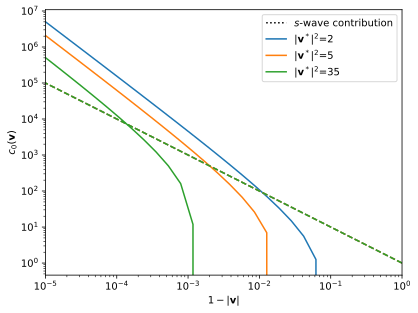

In [8]:
def model(x, a, p):
    return a / x**p


def relDiff(a, b):
    return np.abs(a - b) / (0.5 * np.abs(a + b))


j = 0
z2 = 1.0  # zeta(j)
nPoints = 30
expMax = 5
par = cqedr.tune(j, residual=1.0e-2)
cj0 = cqedr(j, par)
print(cj0)
dir = [1, 1, 0]
cj = cjVsVel(j, dir, nPoints, residual=1.0e-2, expMax=expMax)
sw = cj0 * np.arctanh(1 - cj[0]) / (1 - cj[0])
plt.plot(cj[0], sw, color="black", linestyle=":", label=r"$s$-wave contribution")
plt.plot(
    cj[0],
    cj[1],
    color="C0",
    label=(r"$|\mathbf{v}^*|^2$=%d" % (np.linalg.norm(dir) ** 2)),
)
plt.plot(
    cj[0], model(cj[0], z2 / np.linalg.norm(dir) ** j, 1), color="C0", linestyle="--"
)
dir = [1, 2, 1]
cj = cjVsVel(j, dir, nPoints, residual=1.0e-2, expMax=expMax)
plt.plot(
    cj[0],
    cj[1],
    color="C1",
    label=(r"$|\mathbf{v}^*|^2$=%d" % (np.linalg.norm(dir) ** 2)),
)
plt.plot(
    cj[0], model(cj[0], z2 / np.linalg.norm(dir) ** j, 1), color="C1", linestyle="--"
)
dir = [1, 3, 5]
cj = cjVsVel(j, dir, nPoints, residual=1.0e-2, expMax=expMax)
plt.plot(
    cj[0],
    cj[1],
    color="C2",
    label=(r"$|\mathbf{v}^*|^2$=%d" % (np.linalg.norm(dir) ** 2)),
)
plt.plot(
    cj[0], model(cj[0], z2 / np.linalg.norm(dir) ** j, 1), color="C2", linestyle="--"
)
plt.xscale("log")
plt.yscale("log")
plt.xlabel(r"$1-|\mathbf{v}|$")
plt.ylabel(r"$c_%d(\mathbf{v})$" % (j))
plt.xlim(10.0 ** (-expMax), 1.0)
# plt.ylim(bottom=10)
plt.legend()
plt.show()

-1.0


  0%|          | 0/20 [00:00<?, ?it/s]

(array([0.24024941, 1.50434582]), array([[ 3.11469014e-07, -1.14764662e-07],
       [-1.14764662e-07,  4.23215590e-08]]))


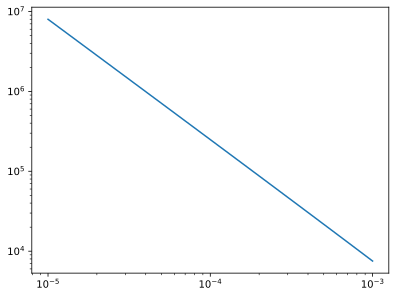

In [40]:
def model(x, a, p):
    return a / x**p


j = 0.0
z2 = 1.0  # zeta(j)
nPoints = 20
expMin = 3
expMax = 5
par = cqedr.tune(j, residual=1.0e-2)
cj0 = cqedr(j, par)
print(cj0)
dir = [1, 0, 0]
cj = cjVsVel(j, dir, nPoints, residual=1.0e-2, expMin=expMin, expMax=expMax)
sw = cj0 * np.arctanh(1 - cj[0]) / (1 - cj[0])
plt.plot(cj[0], sw, color="black", linestyle=":", label=r"$s$-wave contribution")
plt.plot(
    cj[0],
    cj[1],
    color="C0",
    label=(r"$|\mathbf{v}^*|^2$=%d" % (np.linalg.norm(dir) ** 2)),
)
opt = curve_fit(model, cj[0], cj[1])
print(opt)
plt.xscale("log")
plt.yscale("log")
plt.show()

(array([0.24024941, 1.50434582]), array([[ 3.11469014e-07, -1.14764662e-07],
       [-1.14764662e-07,  4.23215590e-08]]))


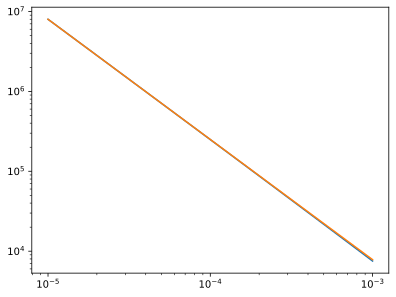

In [41]:
plt.plot(cj[0], sw, color="black", linestyle=":", label=r"$s$-wave contribution")
plt.plot(
    cj[0],
    cj[1],
    color="C0",
)
opt = curve_fit(model, cj[0], cj[1])
plt.plot(
    cj[0],
    model(cj[0], *opt[0]),
    color="C1",
)
print(opt)
plt.xscale("log")
plt.yscale("log")
plt.show()